<a href="https://colab.research.google.com/github/laiajufresa-code/TFG/blob/main/TFG_llibreta1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os, glob, itertools, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import spearmanr
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import kagglehub

warnings.filterwarnings("ignore")
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

path = kagglehub.dataset_download("colabsss/diabetes-risk-monitoring-dataset")
csv_path = glob.glob(os.path.join(path, "**", "*.csv"), recursive=True)[0]
df_raw = pd.read_csv(csv_path)
print(df_raw.shape)

Using Colab cache for faster access to the 'diabetes-risk-monitoring-dataset' dataset.
(15000, 35)


In [ ]:
# ============ PARÀMETRES: es canvien NOMÉS aquí ============
LLINDAR_CORR = 0.70     # pas 1: es considera "altament correlacionat" |rho de Spearman| >= 0,70
ALPHA = 0.05            # pas 2: nivell de significació (sobre p ajustats amb Holm)
CRITERI_DESEMPAT = "efecte"   # pas 1: de cada parella correlacionada, es manté la variable amb MÉS efecte sobre el risc ("efecte")
                              #         o la que té menys correlació mitjana amb la resta ("no_supervisat", sense mirar el risc)
EPS2_MIN = None         # pas 2 (opcional): p. ex. 0.01 per eliminar també efectes "molt petits"; None = només per significació
N_COMP = 5              # pas 3: nombre de components principals (l'enunciat demana 4 o 5)
FITXER_SORTIDA = "dataset_reduit_pca.csv"
# ===========================================================
assert LLINDAR_CORR < 1 and isinstance(N_COMP, int) and 2 <= N_COMP <= 10 and CRITERI_DESEMPAT in ("efecte", "no_supervisat")

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 11, "axes.labelsize": 10})

TARGET = "diabetes_risk_level"
ORDER  = ["Low_Risk", "Moderate_Risk", "High_Risk", "Critical_Risk"]
LABELS = {"Low_Risk": "Low", "Moderate_Risk": "Moderate", "High_Risk": "High", "Critical_Risk": "Critical"}
COLORS = {"Low_Risk": "#2ca02c", "Moderate_Risk": "#f2c94c", "High_Risk": "#f2994a", "Critical_Risk": "#d62728"}
ETIQ = [LABELS[o] for o in ORDER]
PAL4 = [COLORS[o] for o in ORDER]

# Mateixa classificació que a la Llibreta 1
ID_COLS   = ["patient_id", "monitoring_date"]
CAT_BIN   = ["gender", "family_history_diabetes", "medication_change_recent"]
DISC_COLS = ["comorbidity_count", "abnormal_glucose_events", "previous_hypoglycemia_events",
             "outpatient_visits_6m", "daily_monitoring_frequency"]
CONT_COLS = [c for c in df_raw.columns if c not in ID_COLS + CAT_BIN + DISC_COLS + [TARGET]]

# Dataset de treball: sense ID ni data. Les 3 binàries es codifiquen 0/1 NOMÉS per poder-les entrar en
# correlacions i PCA (Male=1, Yes=1). El target queda a part: mai és una variable predictora.
X = df_raw.drop(columns=ID_COLS + [TARGET]).copy()
X["gender"] = (X["gender"] == "Male").astype(int)
for c in ["family_history_diabetes", "medication_change_recent"]:
    X[c] = (X[c] == "Yes").astype(int)
y = pd.Categorical(df_raw[TARGET], categories=ORDER, ordered=True)
y_num = pd.Series(y.codes, index=X.index, name="risk_num")     # només per correlacions/gràfics

PREDICTORES = list(X.columns)
assert len(PREDICTORES) == 32 and X.isna().sum().sum() == 0
assert not set(PREDICTORES) & {TARGET, "patient_id", "monitoring_date"}
print("Variables predictores:", len(PREDICTORES))

def holm(p):
    p = np.asarray(p, float); n = len(p); ordre = np.argsort(p)
    adj = np.empty(n); mx = 0.0
    for rang, i in enumerate(ordre):
        mx = max(mx, (n - rang) * p[i]); adj[i] = min(mx, 1.0)
    return adj

def fmt_p(p):
    return "<0.001" if p < 0.001 else f"{p:.3f}"

def eps2_kw(grups):
    """Kruskal-Wallis: estadístic H i mida d'efecte ε² = (H - k + 1) / (N - k)."""
    H = stats.kruskal(*grups)[0]; N = sum(len(g) for g in grups); k = len(grups)
    return H, (H - k + 1) / (N - k)

def classifica(e):
    """Field (2013): <0,01 molt petit · <0,06 petit · <0,14 mitjà · >=0,14 gran."""
    return "gran" if e >= 0.14 else "mitjà" if e >= 0.06 else "petit" if e >= 0.01 else "molt petit"

def estil(styler, f):
    """Aplica f a cada cel·la (compatible amb pandas < 2.1 i >= 2.1)."""
    return styler.map(f) if hasattr(styler, "map") else styler.applymap(f)

# Mida d'efecte de cada predictora sobre el risc (només per desempatar al pas 1)
eps2_tot = pd.Series({c: eps2_kw([X.loc[y == o, c].values for o in ORDER])[1] for c in PREDICTORES})

# Registre del flux: quantes variables entren, s'eliminen i queden a cada pas
flux = []

Variables predictores: 32


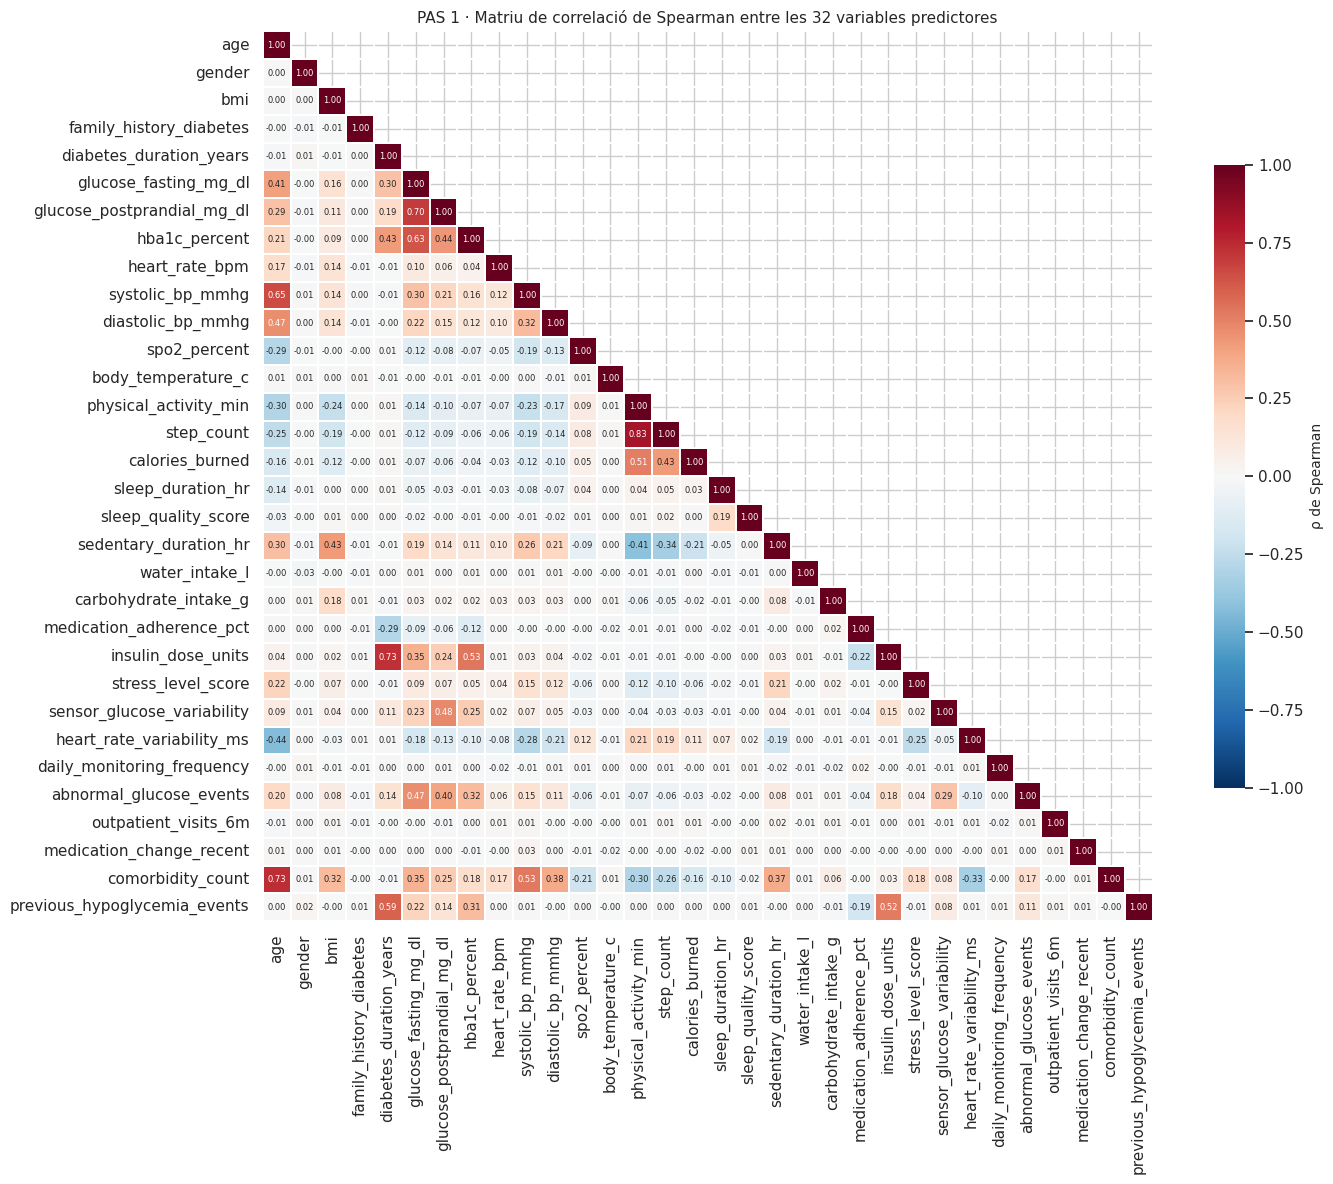

Parelles amb |rho| >= 0.7: 4


,variable A,variable B,rho
0,physical_activity_min,step_count,0.830
1,age,comorbidity_count,0.735
2,diabetes_duration_years,insulin_dose_units,0.729
3,glucose_fasting_mg_dl,glucose_postprandial_mg_dl,0.701



Les 10 parelles més correlacionades (per veure què queda just sota el llindar):


,variable A,variable B,rho
0,physical_activity_min,step_count,0.830
1,age,comorbidity_count,0.735
2,diabetes_duration_years,insulin_dose_units,0.729
3,glucose_fasting_mg_dl,glucose_postprandial_mg_dl,0.701
4,age,systolic_bp_mmhg,0.651
5,glucose_fasting_mg_dl,hba1c_percent,0.625
6,diabetes_duration_years,previous_hypoglycemia_events,0.591
7,hba1c_percent,insulin_dose_units,0.533
8,systolic_bp_mmhg,comorbidity_count,0.528
9,insulin_dose_units,previous_hypoglycemia_events,0.522


In [ ]:
corr_pred = X.corr(method="spearman")

fig, ax = plt.subplots(figsize=(15, 12))
mask = np.triu(np.ones_like(corr_pred, dtype=bool), k=1)
sns.heatmap(corr_pred, mask=mask, cmap="RdBu_r", vmin=-1, vmax=1, center=0, square=True,
            linewidths=0.3, cbar_kws={"shrink": 0.7, "label": "ρ de Spearman"},
            annot=True, fmt=".2f", annot_kws={"size": 6})
ax.set_title("PAS 1 · Matriu de correlació de Spearman entre les 32 variables predictores")
plt.tight_layout(); plt.show()

# Parelles amb |rho| >= llindar, de major a menor
parelles = [(a, b, corr_pred.loc[a, b]) for a, b in itertools.combinations(PREDICTORES, 2)
            if abs(corr_pred.loc[a, b]) >= LLINDAR_CORR]
parelles = sorted(parelles, key=lambda t: -abs(t[2]))
print(f"Parelles amb |rho| >= {LLINDAR_CORR}:", len(parelles))
display(pd.DataFrame(parelles, columns=["variable A", "variable B", "rho"]).round(3))

# Per context: les 10 parelles més fortes, siguin o no sobre el llindar
totes = sorted(((a, b, corr_pred.loc[a, b]) for a, b in itertools.combinations(PREDICTORES, 2)),
               key=lambda t: -abs(t[2]))[:10]
print("\nLes 10 parelles més correlacionades (per veure què queda just sota el llindar):")
display(pd.DataFrame(totes, columns=["variable A", "variable B", "rho"]).round(3))

In [ ]:
def filtre_correlacio(corr, llindar, criteri, efecte):
    """Mentre hi hagi una parella amb |rho| >= llindar, se n'elimina una variable i es torna a mirar.
    criteri="efecte": s'elimina la de MENOR ε² amb el risc (es conserva la més útil per classificar).
    criteri="no_supervisat": s'elimina la de MAJOR correlació absoluta mitjana amb la resta (no mira el risc)."""
    queden = list(corr.columns); registre = []
    while True:
        sub = corr.loc[queden, queden].abs().values.copy()
        np.fill_diagonal(sub, 0)
        i, j = np.unravel_index(np.argmax(sub), sub.shape)
        if sub[i, j] < llindar:
            break
        a, b = queden[i], queden[j]
        mitjana = pd.Series(sub.sum(axis=1) / (len(queden) - 1), index=queden)
        if criteri == "efecte":
            eliminada, mantinguda = (a, b) if efecte[a] < efecte[b] else (b, a)
        else:
            eliminada, mantinguda = (a, b) if mitjana[a] >= mitjana[b] else (b, a)
        registre.append({"parella": f"{a} ~ {b}", "rho": corr.loc[a, b],
                         "ε² A": efecte[a], "ε² B": efecte[b],
                         "|rho| mitjana A": mitjana[a], "|rho| mitjana B": mitjana[b],
                         "s'elimina": eliminada, "es manté": mantinguda})
        queden.remove(eliminada)
    return queden, pd.DataFrame(registre)

passa1, reg1 = filtre_correlacio(corr_pred, LLINDAR_CORR, CRITERI_DESEMPAT, eps2_tot)
elim1 = [c for c in PREDICTORES if c not in passa1]

print(f"PAS 1 · llindar |rho| >= {LLINDAR_CORR} · criteri de desempat: {CRITERI_DESEMPAT}")
if len(reg1):
    display(reg1.round(3))
print(f"Entren: {len(PREDICTORES)} · s'eliminen: {len(elim1)} -> {elim1} · queden: {len(passa1)}")
flux.append({"pas": "1. Correlació", "entren": len(PREDICTORES), "eliminades": len(elim1), "queden": len(passa1),
             "variables eliminades": ", ".join(elim1) if elim1 else "—"})

# Comprovació: ja no queda cap parella per sobre del llindar
sub = corr_pred.loc[passa1, passa1].abs().values.copy(); np.fill_diagonal(sub, 0)
assert sub.max() < LLINDAR_CORR
print("Correlació màxima entre les variables que queden:", round(sub.max(), 3))

PAS 1 · llindar |rho| >= 0.7 · criteri de desempat: efecte


,parella,rho,ε² A,ε² B,|rho| mitjana A,|rho| mitjana B,s'elimina,es manté
0,physical_activity_min ~ step_count,0.830,0.082,0.058,0.132,0.116,step_count,physical_activity_min
1,age ~ comorbidity_count,0.735,0.217,0.177,0.173,0.166,comorbidity_count,age
2,diabetes_duration_years ~ insulin_dose_units,0.729,0.210,0.233,0.101,0.110,diabetes_duration_years,insulin_dose_units
3,glucose_fasting_mg_dl ~ glucose_postprandial_m...,0.701,0.524,0.328,0.170,0.141,glucose_postprandial_mg_dl,glucose_fasting_mg_dl


Entren: 32 · s'eliminen: 4 -> ['diabetes_duration_years', 'glucose_postprandial_mg_dl', 'step_count', 'comorbidity_count'] · queden: 28
Correlació màxima entre les variables que queden: 0.651


In [ ]:
rows = []
for c in passa1:
    g = [X.loc[y == o, c].values for o in ORDER]
    if c in CAT_BIN:                                           # binàries: khi quadrat 2x4 + V de Cramér
        ct = pd.crosstab(X[c], pd.Series(y, index=X.index))
        chi, p, dof, _ = stats.chi2_contingency(ct)
        efecte = np.sqrt(chi / (len(X) * (min(ct.shape) - 1)))
        rows.append({"variable": c, "test": "Khi quadrat", "p": p, "mida_efecte": efecte, "tipus_efecte": "V de Cramér"})
    else:                                                      # numèriques i discretes: Kruskal-Wallis + epsilon²
        H, e2 = eps2_kw(g)
        rows.append({"variable": c, "test": "Kruskal-Wallis", "p": stats.kruskal(*g)[1],
                     "mida_efecte": e2, "tipus_efecte": "ε²"})
sel = pd.DataFrame(rows).set_index("variable")
sel["p_holm"] = holm(sel["p"])
sel["significativa"] = sel["p_holm"] < ALPHA
sel["efecte_ε²"] = [classifica(sel.loc[c, "mida_efecte"]) if sel.loc[c, "tipus_efecte"] == "ε²" else "—" for c in sel.index]

# Comprovació de variància pràcticament nul·la (cap variable constant)
constants = [c for c in passa1 if X[c].nunique() <= 1]
print("Variables constants:", constants)

taula2 = sel.copy()
taula2["p"] = taula2["p"].map(fmt_p); taula2["p_holm"] = taula2["p_holm"].map(fmt_p)
display(taula2.sort_values("mida_efecte", ascending=False).round(4))

Variables constants: []


,test,p,mida_efecte,tipus_efecte,p_holm,significativa,efecte_ε²
variable,,,,,,,
glucose_fasting_mg_dl,Kruskal-Wallis,<0.001,0.5239,ε²,<0.001,True,gran
hba1c_percent,Kruskal-Wallis,<0.001,0.5022,ε²,<0.001,True,gran
insulin_dose_units,Kruskal-Wallis,<0.001,0.2329,ε²,<0.001,True,gran
age,Kruskal-Wallis,<0.001,0.2173,ε²,<0.001,True,gran
abnormal_glucose_events,Kruskal-Wallis,<0.001,0.1916,ε²,<0.001,True,gran
systolic_bp_mmhg,Kruskal-Wallis,<0.001,0.1339,ε²,<0.001,True,mitjà
previous_hypoglycemia_events,Kruskal-Wallis,<0.001,0.1324,ε²,<0.001,True,mitjà
stress_level_score,Kruskal-Wallis,<0.001,0.1226,ε²,<0.001,True,mitjà
physical_activity_min,Kruskal-Wallis,<0.001,0.0820,ε²,<0.001,True,mitjà


PAS 2 · α = 0.05 (p ajustat amb Holm sobre 28 proves)
Entren: 28 · s'eliminen: 7 -> ['gender', 'family_history_diabetes', 'body_temperature_c', 'water_intake_l', 'daily_monitoring_frequency', 'outpatient_visits_6m', 'medication_change_recent'] · queden: 21


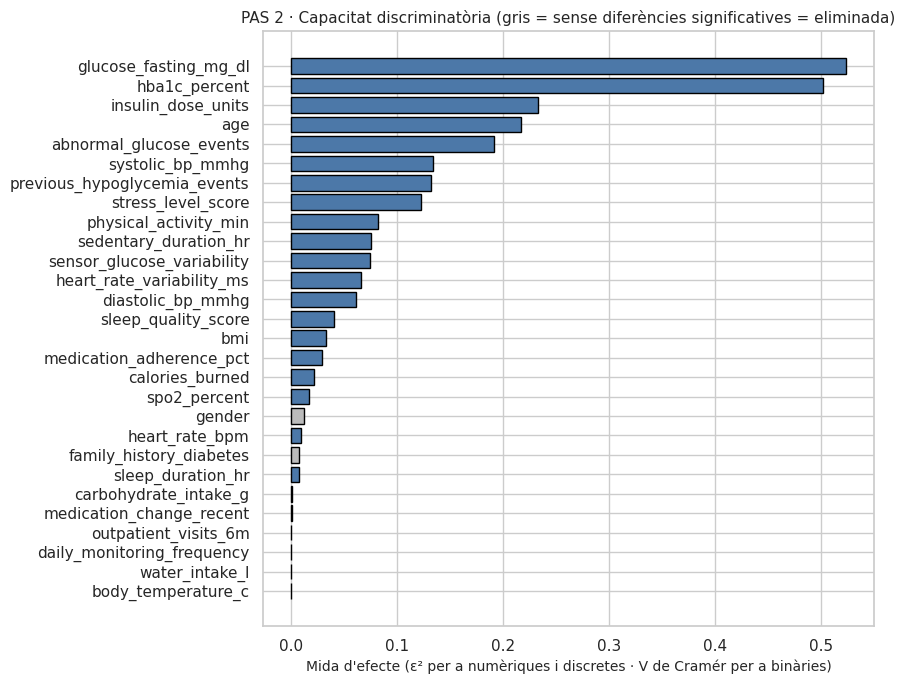

In [ ]:
no_sig = list(sel.index[~sel["significativa"]])
mes_petites = []
if EPS2_MIN is not None:
    mes_petites = [c for c in sel.index[sel["significativa"]]
                   if sel.loc[c, "tipus_efecte"] == "ε²" and sel.loc[c, "mida_efecte"] < EPS2_MIN]
elim2 = no_sig + mes_petites
passa2 = [c for c in passa1 if c not in elim2]

print(f"PAS 2 · α = {ALPHA} (p ajustat amb Holm sobre {len(sel)} proves)" + (f" + ε² mínim = {EPS2_MIN}" if EPS2_MIN else ""))
print(f"Entren: {len(passa1)} · s'eliminen: {len(elim2)} -> {elim2} · queden: {len(passa2)}")
flux.append({"pas": "2. Significació", "entren": len(passa1), "eliminades": len(elim2), "queden": len(passa2),
             "variables eliminades": ", ".join(elim2) if elim2 else "—"})

fig, ax = plt.subplots(figsize=(9, 7))
tr = sel.sort_values("mida_efecte")
ax.barh(tr.index, tr["mida_efecte"], color=["#4C78A8" if s else "#bbbbbb" for s in tr["significativa"]], edgecolor="black")
ax.set_xlabel("Mida d'efecte (ε² per a numèriques i discretes · V de Cramér per a binàries)")
ax.set_title("PAS 2 · Capacitat discriminatòria (gris = sense diferències significatives = eliminada)")
plt.tight_layout(); plt.show()

,component,valor propi,variància explicada (%),acumulada (%)
0,PC1,3.69,17.58,17.58
1,PC2,2.37,11.28,28.86
2,PC3,1.53,7.30,36.16
3,PC4,1.22,5.82,41.98
4,PC5,1.15,5.50,47.48
5,PC6,1.12,5.32,52.80
6,PC7,1.01,4.82,57.62
7,PC8,0.94,4.50,62.12
8,PC9,0.88,4.20,66.32
9,PC10,0.87,4.14,70.46


Variables que entren al PCA: 21 · components amb valor propi > 1 (criteri de Kaiser): 7
Amb 5 components s'explica el 47.5% de la variància total.


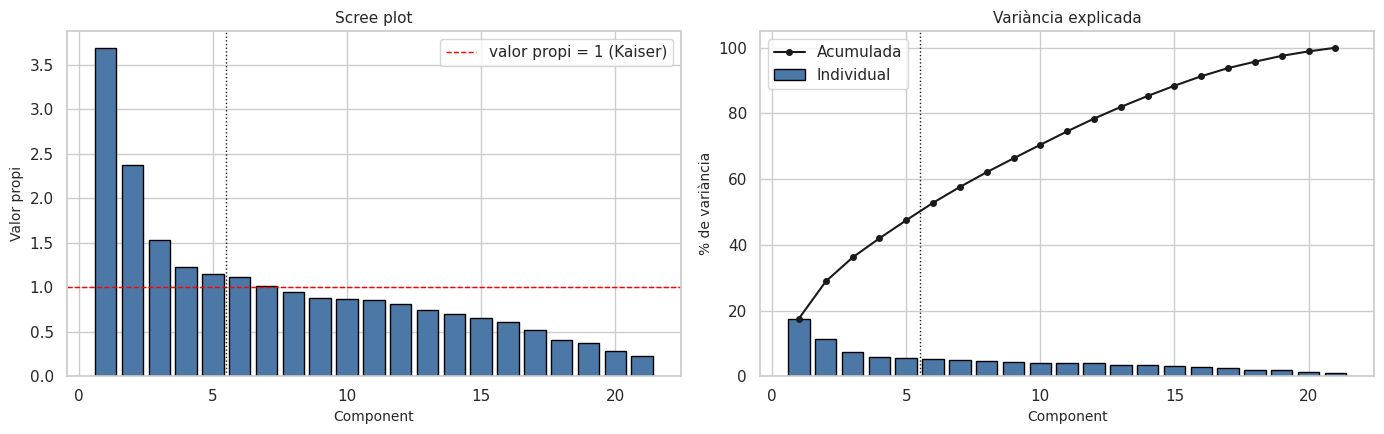

In [ ]:
assert N_COMP <= len(passa2)
X2 = X[passa2]
scaler = StandardScaler()
Z = pd.DataFrame(scaler.fit_transform(X2), columns=passa2, index=X.index)      # mitjana 0, desviació 1
assert np.allclose(Z.mean(), 0, atol=1e-8) and np.allclose(Z.std(ddof=0), 1, atol=1e-8)

pca_complet = PCA(random_state=42).fit(Z)                                      # tots els components, per triar N_COMP amb criteri
var_exp = pca_complet.explained_variance_ratio_
valors_propis = pca_complet.explained_variance_
n_kaiser = int((valors_propis > 1).sum())

scree = pd.DataFrame({"component": [f"PC{i+1}" for i in range(len(var_exp))],
                      "valor propi": valors_propis,
                      "variància explicada (%)": var_exp * 100,
                      "acumulada (%)": np.cumsum(var_exp) * 100})
display(scree.round(2))
print(f"Variables que entren al PCA: {len(passa2)} · components amb valor propi > 1 (criteri de Kaiser): {n_kaiser}")
print(f"Amb {N_COMP} components s'explica el {np.cumsum(var_exp)[N_COMP-1]*100:.1f}% de la variància total.")
flux.append({"pas": "3. PCA", "entren": len(passa2), "eliminades": len(passa2) - N_COMP, "queden": N_COMP,
             "variables eliminades": f"{len(passa2)} variables originals -> {N_COMP} components"})

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].bar(range(1, len(var_exp) + 1), valors_propis, color="#4C78A8", edgecolor="black")
axes[0].axhline(1, color="red", ls="--", lw=1, label="valor propi = 1 (Kaiser)")
axes[0].axvline(N_COMP + 0.5, color="k", ls=":", lw=1)
axes[0].set_xlabel("Component"); axes[0].set_ylabel("Valor propi"); axes[0].set_title("Scree plot"); axes[0].legend()
axes[1].bar(range(1, len(var_exp) + 1), var_exp * 100, color="#4C78A8", edgecolor="black", label="Individual")
axes[1].plot(range(1, len(var_exp) + 1), np.cumsum(var_exp) * 100, "k-o", ms=4, label="Acumulada")
axes[1].axvline(N_COMP + 0.5, color="k", ls=":", lw=1)
axes[1].set_xlabel("Component"); axes[1].set_ylabel("% de variància"); axes[1].set_title("Variància explicada"); axes[1].legend()
plt.tight_layout(); plt.show()

LOADINGS (correlació de cada variable original amb cada component; en negreta |pes| >= 0,40)


,PC1,PC2,PC3,PC4,PC5
age,0.727000,-0.293000,-0.405000,-0.064000,0.065000
bmi,0.327000,-0.175000,0.596000,0.297000,-0.070000
glucose_fasting_mg_dl,0.708000,0.366000,-0.064000,0.211000,-0.033000
hba1c_percent,0.578000,0.572000,0.021000,0.058000,-0.023000
heart_rate_bpm,0.229000,-0.116000,0.024000,0.184000,-0.024000
systolic_bp_mmhg,0.612000,-0.275000,-0.265000,0.007000,0.085000
diastolic_bp_mmhg,0.494000,-0.231000,-0.204000,0.019000,0.035000
spo2_percent,-0.281000,0.136000,0.296000,0.081000,-0.099000
physical_activity_min,-0.490000,0.377000,-0.440000,0.245000,0.020000
calories_burned,-0.323000,0.282000,-0.427000,0.322000,0.029000



EIGENVECTORS (coeficients de la combinació lineal; norma 1 per component)


,PC1,PC2,PC3,PC4,PC5
age,0.378,-0.190,-0.327,-0.058,0.061
bmi,0.170,-0.114,0.481,0.268,-0.066
glucose_fasting_mg_dl,0.368,0.238,-0.052,0.191,-0.031
hba1c_percent,0.301,0.371,0.017,0.052,-0.021
heart_rate_bpm,0.119,-0.075,0.020,0.167,-0.022
systolic_bp_mmhg,0.318,-0.179,-0.214,0.006,0.079
diastolic_bp_mmhg,0.257,-0.150,-0.165,0.017,0.033
spo2_percent,-0.146,0.088,0.239,0.073,-0.092
physical_activity_min,-0.255,0.245,-0.355,0.221,0.019
calories_burned,-0.168,0.183,-0.345,0.291,0.027


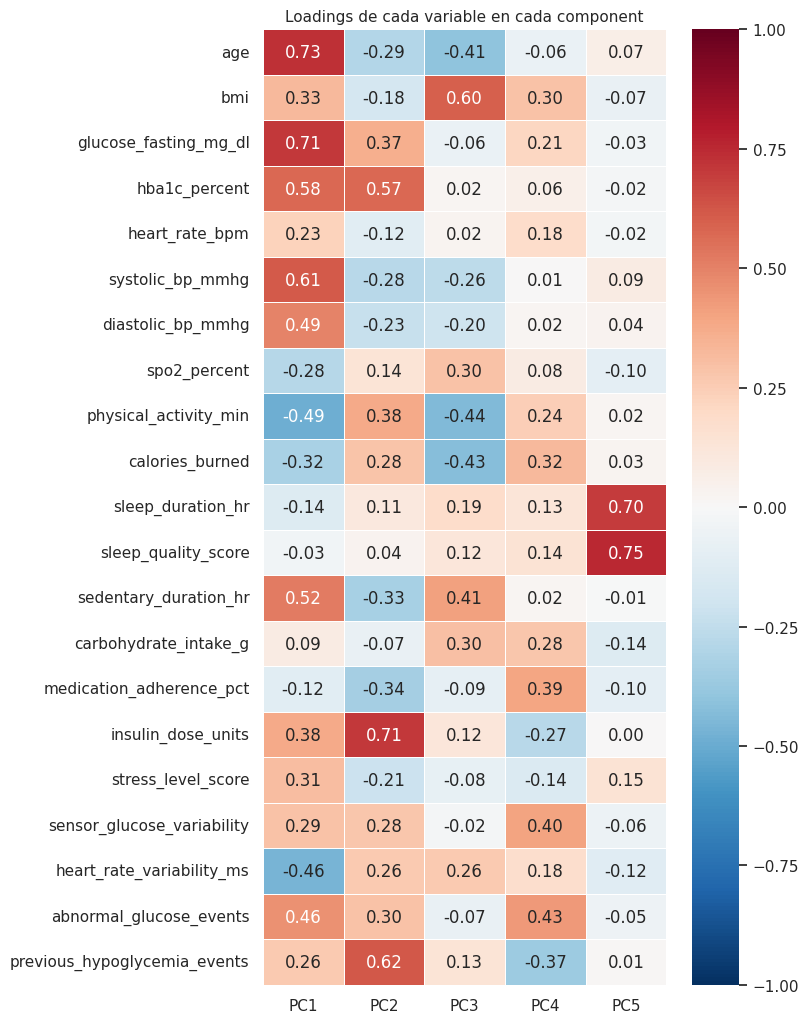

PC1 (17.6%): age (+0.73), glucose_fasting_mg_dl (+0.71), systolic_bp_mmhg (+0.61), hba1c_percent (+0.58)
PC2 (11.3%): insulin_dose_units (+0.71), previous_hypoglycemia_events (+0.62), hba1c_percent (+0.57), physical_activity_min (+0.38)
PC3 (7.3%): bmi (+0.60), physical_activity_min (-0.44), calories_burned (-0.43), sedentary_duration_hr (+0.41)
PC4 (5.8%): abnormal_glucose_events (+0.43), sensor_glucose_variability (+0.40), medication_adherence_pct (+0.39), previous_hypoglycemia_events (-0.37)
PC5 (5.5%): sleep_quality_score (+0.75), sleep_duration_hr (+0.70), stress_level_score (+0.15), carbohydrate_intake_g (-0.14)


In [ ]:
pca = PCA(n_components=N_COMP, random_state=42).fit(Z)
scores = pca.transform(Z)

# Signe: el PCA només defineix cada component llevat del signe. Es fixa de manera determinista
# (la variable amb |pes| més gran de cada component surt positiva) perquè els resultats siguin reproduïbles.
signes = np.sign(pca.components_[np.arange(N_COMP), np.abs(pca.components_).argmax(axis=1)])
pca.components_ = pca.components_ * signes[:, None]
scores = scores * signes
noms_pc = [f"PC{i+1}" for i in range(N_COMP)]

vectors_propis = pd.DataFrame(pca.components_.T, index=passa2, columns=noms_pc)                  # eigenvectors (norma 1)
loadings = vectors_propis * np.sqrt(pca.explained_variance_) / Z.std(ddof=1).values[:, None]          # loadings = correlació variable-component
assert np.allclose(loadings.values, [[np.corrcoef(Z[v], scores[:, k])[0, 1] for k in range(N_COMP)] for v in passa2], atol=1e-6)

print("LOADINGS (correlació de cada variable original amb cada component; en negreta |pes| >= 0,40)")
display(estil(loadings.round(3).style, lambda v: "font-weight:bold;background-color:#c8e6c9" if abs(v) >= 0.40 else ""))
print("\nEIGENVECTORS (coeficients de la combinació lineal; norma 1 per component)")
display(vectors_propis.round(3))

fig, ax = plt.subplots(figsize=(8, 0.4 * len(passa2) + 2))
sns.heatmap(loadings, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, center=0, linewidths=0.4, ax=ax)
ax.set_title("Loadings de cada variable en cada component")
plt.tight_layout(); plt.show()

# Les 4 variables que més pesen a cada component (per interpretar-lo)
for k in noms_pc:
    top = loadings[k].reindex(loadings[k].abs().sort_values(ascending=False).index).head(4)
    print(f"{k} ({pca.explained_variance_ratio_[noms_pc.index(k)]*100:.1f}%): " +
          ", ".join(f"{v} ({l:+.2f})" for v, l in top.items()))

,rho amb el risc,p,ε²,efecte
component,,,,
PC1,0.794,<0.001,0.630,gran
PC2,0.287,<0.001,0.095,mitjà
PC3,-0.015,<0.001,0.002,molt petit
PC4,-0.033,<0.001,0.003,molt petit
PC5,-0.110,<0.001,0.012,petit


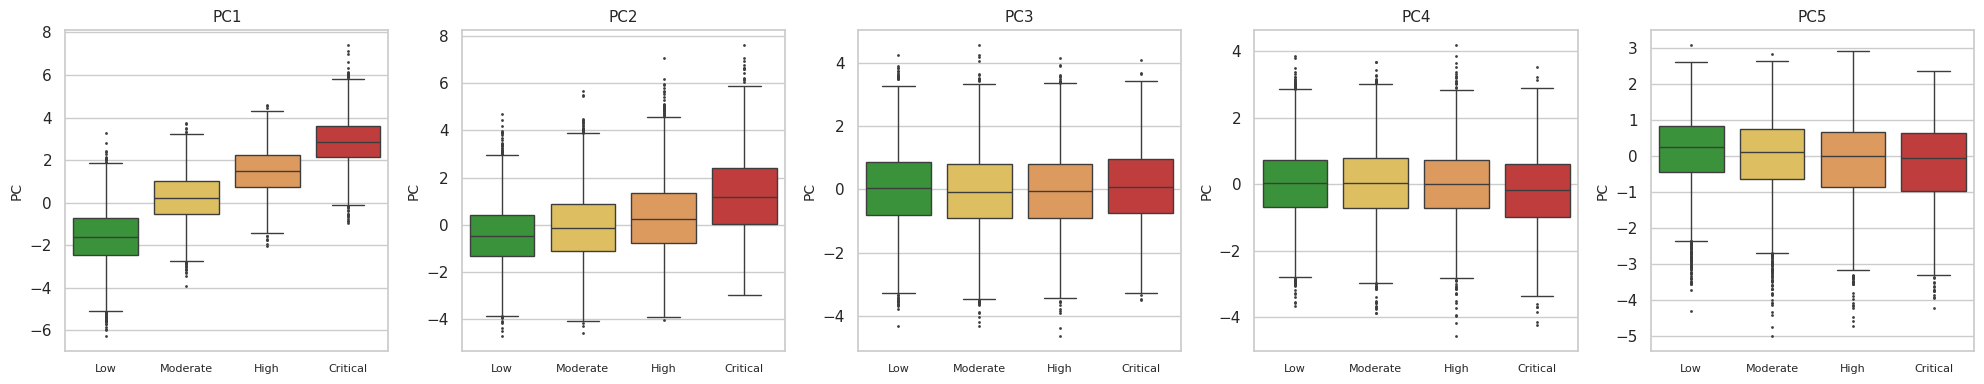

Correlació màxima entre components (ha de ser ~0): 0.0


In [ ]:
sc = pd.DataFrame(scores, columns=noms_pc, index=X.index)
rows = []
for k in noms_pc:
    g = [sc.loc[y == o, k].values for o in ORDER]
    H, e2 = eps2_kw(g)
    rows.append({"component": k, "rho amb el risc": spearmanr(sc[k], y_num)[0],
                 "p": stats.kruskal(*g)[1], "ε²": e2, "efecte": classifica(e2)})
pc_risc = pd.DataFrame(rows).set_index("component")
pc_risc["p"] = pc_risc["p"].map(fmt_p)
display(pc_risc.round(3))

fig, axes = plt.subplots(1, N_COMP, figsize=(4 * N_COMP, 4))
for k, ax in zip(noms_pc, axes):
    plot_df = pd.DataFrame({"PC": sc[k], "risc": pd.Categorical(df_raw[TARGET], categories=ORDER, ordered=True)})
    sns.boxplot(data=plot_df, x="risc", y="PC", order=ORDER, palette=PAL4, ax=ax, fliersize=1, linewidth=1)
    ax.set_xticks(range(4)); ax.set_xticklabels(ETIQ, fontsize=8); ax.set_xlabel(""); ax.set_title(k)
plt.tight_layout(); plt.show()

# Els components són ortogonals entre ells (correlació ≈ 0)
cc = sc.corr().values.copy(); np.fill_diagonal(cc, 0)
print("Correlació màxima entre components (ha de ser ~0):", round(np.abs(cc).max(), 10))

In [ ]:
sortida = sc.copy()
sortida[TARGET] = df_raw[TARGET].values
sortida.to_csv(FITXER_SORTIDA, index=False)

# Metadades per reproduir el PCA a la Llibreta 3 (variables, mitjanes i desviacions del scaler)
meta = pd.DataFrame({"variable": passa2, "mitjana": scaler.mean_, "desviacio": scaler.scale_})
meta.to_csv("metadades_pca.csv", index=False)
loadings.to_csv("loadings_pca.csv")

# Comprovació: es rellegeix el fitxer i es verifica
chk = pd.read_csv(FITXER_SORTIDA)
assert chk.shape == (len(df_raw), N_COMP + 1) and chk.isna().sum().sum() == 0
assert list(chk.columns) == noms_pc + [TARGET]
assert not {"patient_id", "monitoring_date", "risk_num"} & set(chk.columns)
assert set(chk[TARGET].unique()) == set(ORDER)
print(f"Desat: {FITXER_SORTIDA}  ->  {chk.shape[0]} files × {chk.shape[1]} columnes ({N_COMP} components + {TARGET})")
print("Fitxers addicionals: metadades_pca.csv, loadings_pca.csv")
display(chk.head())
display(chk[TARGET].value_counts(normalize=True).reindex(ORDER).round(3).to_frame("proporció"))

# Per descarregar-los a l'ordinador (opcional):
# from google.colab import files
# files.download(FITXER_SORTIDA)

Desat: dataset_reduit_pca.csv  ->  15000 files × 6 columnes (5 components + diabetes_risk_level)
Fitxers addicionals: metadades_pca.csv, loadings_pca.csv


,PC1,PC2,PC3,PC4,PC5,diabetes_risk_level
0,0.626581,2.060018,0.001177,-0.660442,-2.714769,High_Risk
1,0.679563,-0.288323,-2.317408,-0.682665,1.137921,High_Risk
2,-0.046765,-0.945483,1.019683,2.793992,0.570856,Moderate_Risk
3,-1.717658,-0.056531,0.012069,0.267035,0.396211,Low_Risk
4,-0.686607,0.688487,0.387161,0.484349,1.560886,Low_Risk


,proporció
diabetes_risk_level,
Low_Risk,0.4
Moderate_Risk,0.3
High_Risk,0.2
Critical_Risk,0.1


In [ ]:
resum = pd.DataFrame(flux).set_index("pas")
display(resum)
print(f"\nDe {len(PREDICTORES)} variables predictores a {N_COMP} components principals.")
print("Variables que han arribat al PCA:", passa2)

,entren,eliminades,queden,variables eliminades
pas,,,,
1. Correlació,32,4,28,"diabetes_duration_years, glucose_postprandial_..."
2. Significació,28,7,21,"gender, family_history_diabetes, body_temperat..."
3. PCA,21,16,5,21 variables originals -> 5 components



De 32 variables predictores a 5 components principals.
Variables que han arribat al PCA: ['age', 'bmi', 'glucose_fasting_mg_dl', 'hba1c_percent', 'heart_rate_bpm', 'systolic_bp_mmhg', 'diastolic_bp_mmhg', 'spo2_percent', 'physical_activity_min', 'calories_burned', 'sleep_duration_hr', 'sleep_quality_score', 'sedentary_duration_hr', 'carbohydrate_intake_g', 'medication_adherence_pct', 'insulin_dose_units', 'stress_level_score', 'sensor_glucose_variability', 'heart_rate_variability_ms', 'abnormal_glucose_events', 'previous_hypoglycemia_events']
